
# AISE4010 Group 11 ? Stage 2 model workspace

Temporary workspace for developing RNN, LSTM, GRU, and TCN models. It keeps only the shared data/window preparation required to train these models; Stage 1 exploration, baseline/model runs, tables, and embedded data outputs are intentionally omitted.

Input contract: past 168 hourly steps -> next 24 hourly targets. Select candidates with validation-only, measured-hour midnight-origin RMSE. Copy the selected model, configuration, and validation evidence into the final evolving notebook, where Stage 1 models and the final test comparison belong.


In [51]:
import os

# Convert the raw UCI .txt (';'-separated, '?' = missing) to CSV once
if not os.path.exists('household_power_consumption.csv'):
    with open('household_power_consumption.txt', newline='') as src, open('household_power_consumption.csv', 'w', newline='') as dst:
        for line in src:
            dst.write(line.replace(';', ',').replace('?', ''))

In [52]:
import os, sys
os.environ['PATH'] = os.path.join(sys.prefix, 'Library', 'bin') + os.pathsep + os.environ.get('PATH', '')
import torch
print(sys.executable)
print(torch.backends.cudnn.version())

c:\Users\ahaze\anaconda3\envs\4010-DeepLearning\python.exe
92800


In [53]:

import pandas as pd

df = pd.read_csv('household_power_consumption.csv')
df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H:%M:%S')
df = df.drop(columns=['Date', 'Time']).set_index('Datetime')
print('Loaded rows:', len(df), '| coverage:', df.index.min(), '->', df.index.max())


Loaded rows: 2075259 | coverage: 2006-12-16 17:24:00 -> 2010-11-26 21:02:00


### GPU check
Confirms which device PyTorch will train on. Every model below is moved to `device`.

In [54]:
import os
import random
import sys
import numpy as np

os.environ['PATH'] = os.path.join(sys.prefix, 'Library', 'bin') + os.pathsep + os.environ.get('PATH', '')
import torch

print('PyTorch', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
print('CUDA version:', torch.version.cuda, '| cuDNN version:', torch.backends.cudnn.version())

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cuda':
    print('Training on GPU:', torch.cuda.get_device_name(0))
else:
    print('No GPU found, training on CPU')

# A small matmul proves tensors actually land on the chosen device
probe = torch.randn(256, 256, device=device)
print('Test matmul ran on:', (probe @ probe).device)

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)  # also seeds CUDA

# Deterministic cuDNN kernels so GPU runs repeat exactly with the same seed
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
set_seed()

PyTorch 2.14.1
CUDA available: True
CUDA version: 13.4 | cuDNN version: 92800
Training on GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Test matmul ran on: cuda:0


In [55]:
TARGET = 'Global_active_power'
LOOKBACK, HORIZON = 168, 24
DAY, WEEK = 24, 168


## Resampling and imputation
* **Resample:** hourly mean. Hours with fewer than 30 recorded minutes are set to missing.
* **Short gaps (≤ 3 h):** forward fill, which carries the last observed hour forward.
* **Long gaps (up to about 5 days):** the value from the same hour one week earlier. Any remainder is forward-filled.

Every fill is **causal**: a missing hour is filled only from earlier hours. Interpolation would use the next observed hour, which could be a target hour of the same window. Nothing here is fitted to data either, so imputation cannot leak test statistics into training. The `imputed` mask is kept so we can report how much of each split is filled in.

In [56]:
counts = df[TARGET].resample('h').count()
hourly_raw = df.resample('h').mean()
hourly_raw.loc[counts < 30] = np.nan
imputed = hourly_raw[TARGET].isna()

# Length of each run of missing hours
run_id = (imputed != imputed.shift()).cumsum()
run_len = imputed.groupby(run_id).transform('size')
short_gap = imputed & (run_len <= 3)

hourly = hourly_raw.copy()
hourly.loc[short_gap] = hourly_raw.ffill().loc[short_gap]
for _ in range(2):  # a second pass covers gaps whose previous week was also missing
    hourly = hourly.fillna(hourly.shift(WEEK))
hourly = hourly.ffill().dropna()  # only leading hours with no history can remain; drop them
imputed = imputed.loc[hourly.index]

assert not hourly.isna().any().any()
print(f'Hourly rows: {len(hourly)} | imputed hours: {imputed.sum()} ({imputed.mean():.2%}), '
      f'of which short gaps: {short_gap.sum()}')

Hourly rows: 34589 | imputed hours: 432 (1.25%), of which short gaps: 7


## Shared forecast setup
This compact setup reproduces only the preprocessing and window definitions required by the Stage 2 models. The same chronological 60/20/20 split is used. Scalers and the profile baseline are fitted on training rows only. The Stage 1-selected feature configuration is retained for a fair comparison when the selected Stage 2 model is later integrated into the final notebook.

Each model receives the past 168 hourly feature rows and the known calendar features for each of the 24 forecast timestamps (hour, weekday, weekend, and annual position). Future power measurements are never provided as inputs.


In [57]:
features = hourly.copy()
idx = features.index
dow = idx.day_of_week.to_numpy()
year_phase = 2 * np.pi * ((idx.day_of_year.to_numpy() - 1) + idx.hour.to_numpy() / 24) / 365.2425
features['hour_sin'] = np.sin(2 * np.pi * idx.hour / 24)
features['hour_cos'] = np.cos(2 * np.pi * idx.hour / 24)
features['dow_sin'] = np.sin(2 * np.pi * dow / 7)
features['dow_cos'] = np.cos(2 * np.pi * dow / 7)
features['is_weekend'] = (dow >= 5).astype(float)
for harmonic in (1, 2):
    features[f'year_sin_{harmonic}'] = np.sin(harmonic * year_phase)
    features[f'year_cos_{harmonic}'] = np.cos(harmonic * year_phase)

# Calendar values for forecast timestamps are known at prediction time.
FUTURE_CALENDAR_FEATURES = [
    'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend',
    'year_sin_1', 'year_cos_1', 'year_sin_2', 'year_cos_2',
]

past_gap = hourly[TARGET]
causal_mean = past_gap.shift(1).expanding(min_periods=1).mean().fillna(past_gap.iloc[0])
annual_index = idx - pd.DateOffset(years=1)
annual_lag = past_gap.reindex(annual_index).to_numpy()
features['GAP_lag_1y_available'] = np.isfinite(annual_lag).astype(float)
features['GAP_lag_1y'] = np.where(np.isfinite(annual_lag), annual_lag, causal_mean.to_numpy())
for days in (7, 28):
    trailing = past_gap.shift(1).rolling(days * 24, min_periods=24).mean()
    features[f'GAP_mean_{days}d'] = trailing.fillna(causal_mean)

n = len(features)
train_end, val_end = int(n * 0.6), int(n * 0.8)
splits = {'train': (0, train_end), 'val': (train_end, val_end), 'test': (val_end, n)}
pd.DataFrame([{'split': s, 'start': features.index[a], 'end': features.index[b - 1], 'hours': b - a,
               'imputed %': round(imputed.iloc[a:b].mean() * 100, 2)}
              for s, (a, b) in splits.items()]).set_index('split')


,start,end,hours,imputed %
split,,,,
train,2006-12-16 17:00:00,2009-04-29 09:00:00,20753,0.33
val,2009-04-29 10:00:00,2010-02-11 15:00:00,6918,1.76
test,2010-02-11 16:00:00,2010-11-26 21:00:00,6918,3.50



### Causal seasonal baseline
The Stage 1-selected `profile` baseline (hour-of-week mean, fitted on training rows) is retained to match the established Stage 1 input/target representation. Calendar features and rolling/annual features are generated causally; no centered or future-looking features are used.


In [58]:

gap = hourly[TARGET].to_numpy()
how = (features.index.day_of_week * 24 + features.index.hour).to_numpy()
profile = pd.Series(gap[:train_end]).groupby(how[:train_end]).mean()
weekly_profile = profile.reindex(how).to_numpy()
train_residual = gap[:train_end] - weekly_profile[:train_end]
month_effect = pd.Series(train_residual).groupby(features.index.month[:train_end]).mean()
annual_adjustment = pd.Series(features.index.month).map(month_effect).fillna(0.0).to_numpy()
annual_profile = weekly_profile + annual_adjustment
seasonal_base = {
    'none': np.zeros(n),
    'week': np.r_[np.full(WEEK, np.nan), gap[:-WEEK]],
    'profile': weekly_profile,
    'profile_year': annual_profile,
}


In [59]:
from sklearn.preprocessing import StandardScaler

def to_kw(y, split):
    """Undo target scaling and add the training-fitted seasonal baseline back in kW."""
    return y * x_scaler.scale_[TARGET_IDX] + x_scaler.mean_[TARGET_IDX] + base[split]

def make_windows(start, end):
    """Windows whose 24-hour target lies in [start, end); lookback may use earlier rows."""
    t = np.arange(max(start, LOOKBACK + WEEK), end - HORIZON + 1)
    X = np.stack([X_all[i - LOOKBACK:i] for i in t])
    y = np.stack([X_all[i:i + HORIZON, TARGET_IDX] for i in t])
    return X, y, t

def prepare(variant, drop):
    """Scale inputs and build windows; keep known future calendar separate from observed history."""
    global FEATURES, TARGET_IDX, x_scaler, X_all, data, base, measured, daily_origin, Y_kw
    global X_train, y_train, X_val, y_val, future_calendar
    frame = features.drop(columns=drop)
    target_col = TARGET
    if variant != 'none':
        frame['GAP_resid'] = gap - seasonal_base[variant]
        target_col = 'GAP_resid'
    FEATURES = list(frame.columns)
    TARGET_IDX = FEATURES.index(target_col)
    x_scaler = StandardScaler().fit(frame.iloc[:train_end])
    X_all = x_scaler.transform(frame).astype(np.float32)

    data = {s: make_windows(a, b) for s, (a, b) in splits.items()}
    future_calendar = {
        s: np.stack([
            features.iloc[i:i + HORIZON][FUTURE_CALENDAR_FEATURES].to_numpy(dtype=np.float32)
            for i in windows[2]
        ])
        for s, windows in data.items()
    }
    hours = {s: t[:, None] + np.arange(HORIZON) for s, (_, _, t) in data.items()}
    base = {s: seasonal_base[variant][h] for s, h in hours.items()}
    measured = {s: ~imputed.to_numpy()[h] for s, h in hours.items()}
    daily_origin = {s: features.index[t].hour.to_numpy() == 0 for s, (_, _, t) in data.items()}
    Y_kw = {s: to_kw(y, s) for s, (_, y, _) in data.items()}

    X_train, y_train, t_train = data['train']
    X_val, y_val, t_val = data['val']
    assert X_train.shape[1:] == (LOOKBACK, len(FEATURES)) and y_train.shape[1] == HORIZON
    assert future_calendar['train'].shape[1:] == (HORIZON, len(FUTURE_CALENDAR_FEATURES))
    assert t_train[-1] + HORIZON <= train_end and t_val[-1] + HORIZON <= val_end
    assert all(np.isfinite(X).all() for X, _, _ in data.values())
    assert all(np.isfinite(F).all() for F in future_calendar.values())
    for s, h in hours.items():
        assert np.allclose(Y_kw[s], gap[h], atol=1e-3)

best_variant = 'profile'
best_drop = ['Global_intensity', 'Voltage', 'Global_reactive_power']
prepare(best_variant, best_drop)
print('Training windows:', X_train.shape, '| 24-hour targets:', y_train.shape[1])
print('Known future calendar:', future_calendar['train'].shape)


Training windows: (20394, 168, 18) | 24-hour targets: 24
Known future calendar: (20394, 24, 9)


In [60]:
import copy
import time
from torch import nn

BATCH = 64
MAX_EPOCHS, PATIENCE = 150, 15

def evaluate(y_true, y_pred, mask=None):
    error = y_pred - y_true
    if mask is not None:
        error = error[mask]
    return {'MAE': np.abs(error).mean(), 'RMSE': np.sqrt(np.mean(error ** 2))}

def count_params(model):
    return sum(parameter.numel() for parameter in model.parameters())

def predict(model, X, future):
    model.eval()
    with torch.no_grad():
        batches = [
            model(x_batch.to(device), future_batch.to(device)).cpu()
            for x_batch, future_batch in zip(
                torch.from_numpy(X).split(1024), torch.from_numpy(future).split(1024)
            )
        ]
    return torch.cat(batches).numpy()

def fit(build, train, val, lr=1e-4, batch_size=BATCH, weight_decay=1e-2,
        max_epochs=MAX_EPOCHS, patience=PATIENCE, val_mask=None):
    """Train with optionally masked validation-MSE early stopping."""
    set_seed()
    model = build().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.MSELoss()
    X_train_device, y_train_device, future_train_device = (
        torch.from_numpy(array).to(device) for array in train
    )
    X_val_device, y_val_device, future_val_device = (
        torch.from_numpy(array).to(device) for array in val
    )
    val_mask_device = None if val_mask is None else torch.as_tensor(val_mask, dtype=torch.bool, device=device)
    if val_mask_device is not None and val_mask_device.shape != y_val_device.shape:
        raise ValueError('val_mask must have the same shape as validation targets')
    history = {'train': [], 'val': []}
    best_loss, best_state, wait = float('inf'), copy.deepcopy(model.state_dict()), 0
    start = time.perf_counter()
    for _ in range(max_epochs):
        model.train()
        total_loss = 0.0
        for indices in torch.randperm(len(X_train_device), device=device).split(batch_size):
            optimizer.zero_grad()
            prediction = model(X_train_device[indices], future_train_device[indices])
            loss = loss_fn(prediction, y_train_device[indices])
            loss.backward()
            optimizer.step()
            total_loss += loss.detach() * len(indices)
        model.eval()
        validation_sum, validation_count = 0.0, 0
        with torch.no_grad():
            for batch_start in range(0, len(X_val_device), 1024):
                batch_end = batch_start + 1024
                prediction = model(
                    X_val_device[batch_start:batch_end],
                    future_val_device[batch_start:batch_end],
                )
                squared_error = (prediction - y_val_device[batch_start:batch_end]).square()
                if val_mask_device is not None:
                    squared_error = squared_error[val_mask_device[batch_start:batch_end]]
                validation_sum += squared_error.sum().item()
                validation_count += squared_error.numel()
        if validation_count == 0:
            raise ValueError('Validation mask contains no targets')
        validation_loss = validation_sum / validation_count
        history['train'].append(total_loss.item() / len(X_train_device))
        history['val'].append(validation_loss)
        if validation_loss < best_loss:
            best_loss, wait = validation_loss, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, history, time.perf_counter() - start


## Stage 2 ? recurrent models and TCN
Compare a vanilla RNN, LSTM, GRU, and TCN using the same Stage 1-selected features, chronological split, and training procedure. Each family gets 16 validation-search configurations crossing four architectures with learning rates 1e-4, 3e-4, 1e-3, and 3e-3. Each fit allows up to 150 epochs with 15-epoch early stopping on measured daily-start validation targets, matching the trial-ranking metric. Models receive the past 168 hours plus known calendar features for the forecast timestamps; they never receive future power values.


In [61]:
# Confirm the unchanged forecasting contract before fitting additional models.
assert X_train.shape[1] == LOOKBACK == 168
assert y_train.shape[1] == HORIZON == 24
assert future_calendar['train'].shape[1] == HORIZON

class RecurrentForecaster(nn.Module):
    def __init__(self, cell='GRU', hidden=64, layers=1, dropout=0.1):
        super().__init__()
        recurrent = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[cell]
        self.encoder = recurrent(
            input_size=len(FEATURES), hidden_size=hidden, num_layers=layers,
            batch_first=True, dropout=dropout if layers > 1 else 0.0,
        )
        self.head = nn.Sequential(
            nn.Linear(hidden + len(FUTURE_CALENDAR_FEATURES), hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1),
        )

    def forward(self, x, future_calendar):
        sequence, _ = self.encoder(x)
        context = sequence[:, -1:, :].expand(-1, HORIZON, -1)
        decoder_input = torch.cat([context, future_calendar], dim=-1)
        return self.head(decoder_input).squeeze(-1)

class CausalConv1d(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, dilation):
        super().__init__()
        self.left_padding = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(
            in_channels, out_channels, kernel_size,
            padding=self.left_padding, dilation=dilation,
        )

    def forward(self, x):
        output = self.conv(x)
        if self.left_padding:
            output = output[..., :-self.left_padding]
        return output

class TemporalBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, dilation, dropout):
        super().__init__()
        self.conv1 = CausalConv1d(in_channels, out_channels, kernel_size, dilation)
        self.conv2 = CausalConv1d(out_channels, out_channels, kernel_size, dilation)
        self.dropout = nn.Dropout(dropout)
        self.activation = nn.ReLU()
        self.skip = nn.Conv1d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()

    def forward(self, x):
        residual = self.skip(x)
        output = self.dropout(self.activation(self.conv1(x)))
        output = self.dropout(self.activation(self.conv2(output)))
        return self.activation(output + residual)

class TCNForecaster(nn.Module):
    def __init__(self, hidden=32, layers=6, dropout=0.1, kernel_size=3):
        super().__init__()
        blocks = []
        in_channels = len(FEATURES)
        for level in range(layers):
            blocks.append(TemporalBlock(
                in_channels, hidden, kernel_size, dilation=2 ** level, dropout=dropout,
            ))
            in_channels = hidden
        self.encoder = nn.Sequential(*blocks)
        self.head = nn.Sequential(
            nn.Linear(hidden + len(FUTURE_CALENDAR_FEATURES), hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1),
        )

    def forward(self, x, future_calendar):
        encoded = self.encoder(x.transpose(1, 2))
        context = encoded[:, :, -1].unsqueeze(1).expand(-1, HORIZON, -1)
        decoder_input = torch.cat([context, future_calendar], dim=-1)
        return self.head(decoder_input).squeeze(-1)

stage2_builders = {
    'RNN': lambda **config: RecurrentForecaster(cell='RNN', **config),
    'LSTM': lambda **config: RecurrentForecaster(cell='LSTM', **config),
    'GRU': lambda **config: RecurrentForecaster(cell='GRU', **config),
    'TCN': lambda **config: TCNForecaster(**config),
}


### Equal-budget Stage 2 comparison
Each model consumes `(batch, 168, features)` plus calendar covariates shaped `(batch, 24, calendar_features)` and predicts `(batch, 24)`. The TCN uses causal dilated convolutions with a receptive field covering the one-week input. All four families receive 16 tuning trials crossing four architecture choices with four learning rates. Family/model selection and early stopping use measured daily-start validation targets; all-hour results are reported as a diagnostic.


RNN trial 1/16: daily-start RMSE=0.6103 kW
RNN trial 2/16: daily-start RMSE=0.6104 kW
RNN trial 3/16: daily-start RMSE=0.6078 kW
RNN trial 4/16: daily-start RMSE=0.6043 kW
RNN trial 5/16: daily-start RMSE=0.6143 kW
RNN trial 6/16: daily-start RMSE=0.6114 kW
RNN trial 7/16: daily-start RMSE=0.6098 kW
RNN trial 8/16: daily-start RMSE=0.6061 kW
RNN trial 9/16: daily-start RMSE=0.6138 kW
RNN trial 10/16: daily-start RMSE=0.6146 kW
RNN trial 11/16: daily-start RMSE=0.6110 kW
RNN trial 12/16: daily-start RMSE=0.6065 kW
RNN trial 13/16: daily-start RMSE=0.6131 kW
RNN trial 14/16: daily-start RMSE=0.6141 kW
RNN trial 15/16: daily-start RMSE=0.6062 kW
RNN trial 16/16: daily-start RMSE=0.6014 kW
LSTM trial 1/16: daily-start RMSE=0.6125 kW
LSTM trial 2/16: daily-start RMSE=0.6111 kW
LSTM trial 3/16: daily-start RMSE=0.6116 kW
LSTM trial 4/16: daily-start RMSE=0.6153 kW
LSTM trial 5/16: daily-start RMSE=0.6151 kW
LSTM trial 6/16: daily-start RMSE=0.6153 kW
LSTM trial 7/16: daily-start RMSE=0.6141 

,hidden,layers,dropout,lr,val MAE (daily starts),val RMSE (daily starts),val MAE (all hours),val RMSE (all hours),parameters,training time (s),epochs,kernel_size
family,,,,,,,,,,,,
RNN,128,2,0.2,0.003,0.4337,0.6014,0.4393,0.6107,69761,30.7186,27,NaN
GRU,64,1,0.1,0.003,0.4375,0.6079,0.4393,0.6089,20929,16.8222,16,NaN
LSTM,128,2,0.2,0.003,0.4384,0.6102,0.4397,0.6096,225665,38.6973,16,NaN
TCN,64,6,0.2,0.003,0.4370,0.6131,0.4390,0.6117,145409,54.5991,16,3.0


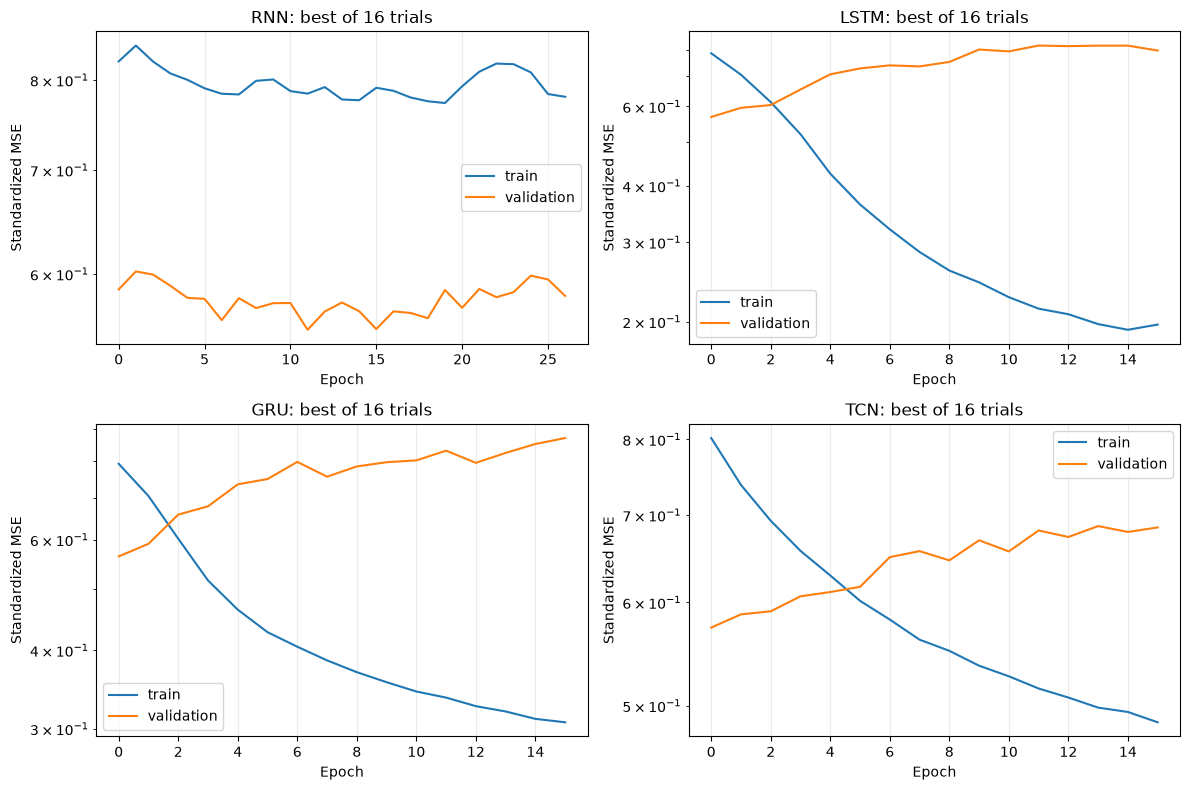

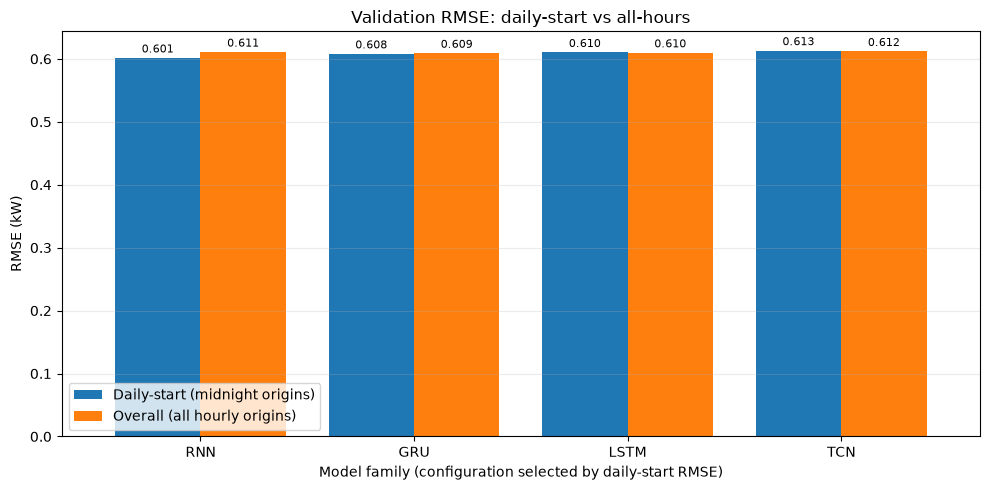

In [62]:
import os
import matplotlib.pyplot as plt

# Sixteen comparable configurations are evaluated for every family (64 fits total).
learning_rates = [1e-4, 3e-4, 1e-3, 3e-3]
recurrent_architectures = [
    {'hidden': 32, 'layers': 1, 'dropout': 0.0},
    {'hidden': 64, 'layers': 1, 'dropout': 0.1},
    {'hidden': 64, 'layers': 2, 'dropout': 0.1},
    {'hidden': 128, 'layers': 2, 'dropout': 0.2},
]
tcn_architectures = [
    {'hidden': 16, 'layers': 4, 'dropout': 0.0, 'kernel_size': 3},
    {'hidden': 32, 'layers': 4, 'dropout': 0.1, 'kernel_size': 3},
    {'hidden': 32, 'layers': 6, 'dropout': 0.1, 'kernel_size': 3},
    {'hidden': 64, 'layers': 6, 'dropout': 0.2, 'kernel_size': 3},
]
recurrent_trials = [
    {**architecture, 'lr': lr}
    for architecture in recurrent_architectures
    for lr in learning_rates
]
tcn_trials = [
    {**architecture, 'lr': lr}
    for architecture in tcn_architectures
    for lr in learning_rates
]

train_data = (X_train, y_train, future_calendar['train'])
val_data = (X_val, y_val, future_calendar['val'])
stage2_daily_mask = measured['val'] & daily_origin['val'][:, None]
stage2_all_mask = measured['val']
stage2_best_by_family, stage2_trials = {}, []

for family in stage2_builders:
    configs = tcn_trials if family == 'TCN' else recurrent_trials
    family_best = {'val RMSE (daily starts)': float('inf')}
    for trial_index, config in enumerate(configs, start=1):
        model_config = {key: value for key, value in config.items() if key != 'lr'}
        model, history, secs = fit(
            lambda family=family, model_config=model_config: stage2_builders[family](**model_config),
            train_data, val_data,
            lr=config['lr'], batch_size=BATCH, weight_decay=1e-2,
            val_mask=stage2_daily_mask,
        )
        prediction_kw = to_kw(
            predict(model, X_val, future_calendar['val']), 'val'
        )
        daily_metrics = evaluate(Y_kw['val'], prediction_kw, stage2_daily_mask)
        all_metrics = evaluate(Y_kw['val'], prediction_kw, stage2_all_mask)
        row = {
            'family': family, **config,
            'val MAE (daily starts)': daily_metrics['MAE'],
            'val RMSE (daily starts)': daily_metrics['RMSE'],
            'val MAE (all hours)': all_metrics['MAE'],
            'val RMSE (all hours)': all_metrics['RMSE'],
            'parameters': count_params(model), 'training time (s)': secs,
            'epochs': len(history['val']),
        }
        stage2_trials.append(row)
        if daily_metrics['RMSE'] < family_best['val RMSE (daily starts)']:
            family_best = {
                **row, 'model': model, 'history': history,
                'config': model_config,
                'train_config': {'lr': config['lr'], 'batch_size': BATCH, 'weight_decay': 1e-2},
            }
        print(f'{family} trial {trial_index}/{len(configs)}: daily-start RMSE={daily_metrics["RMSE"]:.4f} kW')
    stage2_best_by_family[family] = family_best

stage2_hpo_results = pd.DataFrame(stage2_trials).sort_values(
    ['family', 'val RMSE (daily starts)']
)
stage2_family_results = pd.DataFrame([
    {key: value for key, value in best.items() if key not in ('model', 'history', 'config', 'train_config')}
    for best in stage2_best_by_family.values()
]).set_index('family').sort_values('val RMSE (daily starts)')
print('Best configuration per family (all tuning/selection uses validation only):')
display(stage2_family_results.round(4))

# Best family learning curves help distinguish optimization/underfit from overfit.
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=False)
for ax, (family, best) in zip(axes.flat, stage2_best_by_family.items()):
    ax.plot(best['history']['train'], label='train')
    ax.plot(best['history']['val'], label='validation')
    ax.set(title=f'{family}: best of {len(tcn_trials if family == "TCN" else recurrent_trials)} trials', xlabel='Epoch', ylabel='Standardized MSE')
    ax.set_yscale('log')
    ax.grid(True, alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

# Compare both validation RMSE definitions for each family's daily-start winner.
metric_names = ['val RMSE (daily starts)', 'val RMSE (all hours)']
rmse_by_family = stage2_family_results[metric_names]
ax = rmse_by_family.plot(kind='bar', figsize=(10, 5), width=0.8)
ax.set_title('Validation RMSE: daily-start vs all-hours')
ax.set_xlabel('Model family (configuration selected by daily-start RMSE)')
ax.set_ylabel('RMSE (kW)')
ax.set_xticklabels(rmse_by_family.index, rotation=0)
ax.grid(axis='y', alpha=0.25)
ax.legend(['Daily-start (midnight origins)', 'Overall (all hourly origins)'])
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=2, fontsize=8)
plt.tight_layout()
plt.show()


### Validation-only tuning and diagnostics
Each Stage 2 family gets 16 trials crossing four architecture choices with four learning rates (1e-4, 3e-4, 1e-3, and 3e-3). Early stopping and model ranking both use measured daily-start validation targets; all-hours RMSE is reported as a diagnostic. Fits allow up to 150 epochs with 15-epoch early-stopping patience; batch size, weight decay, seed, split, and windows are fixed. The selected model's measured-hour RMSE is also broken down by forecast lead hour. Learning curves compare training and validation losses to help distinguish underfitting from overfitting. The held-out test split is not used here.


Selected RNN using validation daily-start RMSE: 0.6014 kW
Lead-hour errors for selected model (midnight-origin forecasts):


,RMSE (kW),MAE (kW),measured observations
forecast hour,,,
1,0.4028,0.3043,283
2,0.3700,0.2527,282
3,0.3024,0.1950,282
4,0.2612,0.1732,282
5,0.2568,0.1827,282
6,0.3110,0.2296,281
7,0.3686,0.2865,281
8,0.6625,0.5299,281
9,0.5098,0.3853,282


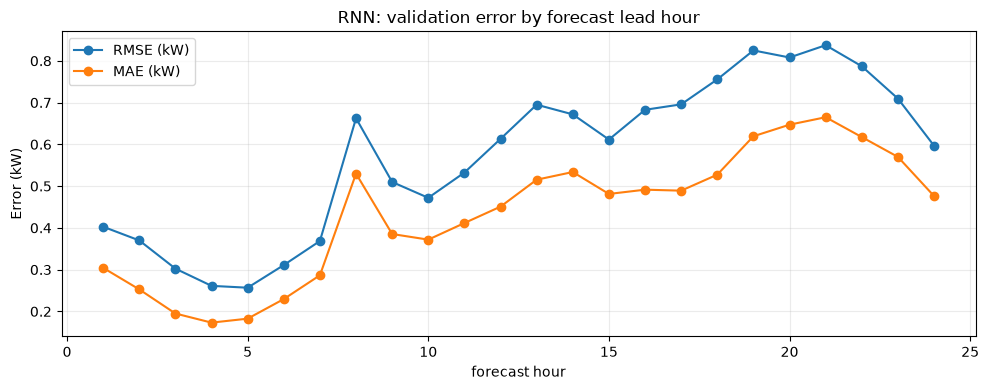

Saved and reloaded Stage 2 checkpoint; smoke forecast shape: (8, 24)


In [63]:
# Lock the best Stage 2 family using daily-start validation RMSE, then inspect lead-hour errors.
stage2_family = stage2_family_results.index[0]
stage2_best = stage2_best_by_family[stage2_family]
stage2_tuned = stage2_best['model']
stage2_tuned_name = f'{stage2_family} (Stage 2 tuned)'
stage2_tuned_inference = None

def inference_ms_per_1000_windows(model, X, future, repeats=3):
    sample, future_sample = X[:min(1024, len(X))], future[:min(1024, len(future))]
    predict(model, sample, future_sample)
    if device.type == 'cuda':
        torch.cuda.synchronize(device)
    start = time.perf_counter()
    for _ in range(repeats):
        predict(model, sample, future_sample)
    if device.type == 'cuda':
        torch.cuda.synchronize(device)
    elapsed = time.perf_counter() - start
    return elapsed * 1_000_000 / (repeats * len(sample))

stage2_tuned_inference = inference_ms_per_1000_windows(
    stage2_tuned, X_val, future_calendar['val']
)

prediction_kw = to_kw(
    predict(stage2_tuned, X_val, future_calendar['val']), 'val'
)
daily_error = prediction_kw - Y_kw['val']
daily_rows = daily_origin['val']
lead_rows = []
for lead_hour in range(HORIZON):
    valid = measured['val'][daily_rows, lead_hour]
    errors = daily_error[daily_rows, lead_hour][valid]
    lead_rows.append({
        'forecast hour': lead_hour + 1,
        'RMSE (kW)': np.sqrt(np.mean(errors ** 2)),
        'MAE (kW)': np.mean(np.abs(errors)),
        'measured observations': len(errors),
    })
stage2_horizon_errors = pd.DataFrame(lead_rows).set_index('forecast hour')
print(f'Selected {stage2_family} using validation daily-start RMSE: {stage2_best["val RMSE (daily starts)"]:.4f} kW')
print('Lead-hour errors for selected model (midnight-origin forecasts):')
display(stage2_horizon_errors.round(4))
stage2_horizon_errors[['RMSE (kW)', 'MAE (kW)']].plot(
    figsize=(10, 4), marker='o', title=f'{stage2_family}: validation error by forecast lead hour'
)
plt.ylabel('Error (kW)')
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

os.makedirs('models', exist_ok=True)
torch.save({
    'stage': 2,
    'family': stage2_family,
    'config': stage2_best['config'],
    'train_config': stage2_best['train_config'],
    'state_dict': stage2_tuned.state_dict(),
    'variant': best_variant,
    'dropped': best_drop,
    'lookback': LOOKBACK,
    'horizon': HORIZON,
    'target': TARGET,
    'features': FEATURES,
    'future_calendar_features': FUTURE_CALENDAR_FEATURES,
    'x_mean': x_scaler.mean_.tolist(),
    'x_scale': x_scaler.scale_.tolist(),
}, 'models/stage2_best.pt')

# Reload the selected checkpoint to check that its 168-hour -> 24-hour interface is reproducible.
checkpoint = torch.load('models/stage2_best.pt', map_location=device)
reloaded_stage2 = stage2_builders[checkpoint['family']](**checkpoint['config']).to(device)
reloaded_stage2.load_state_dict(checkpoint['state_dict'])
smoke_forecast = predict(
    reloaded_stage2, X_val[:8], future_calendar['val'][:8]
)
assert smoke_forecast.shape == (8, HORIZON) and np.isfinite(smoke_forecast).all()
print('Saved and reloaded Stage 2 checkpoint; smoke forecast shape:', smoke_forecast.shape)
